## Laboratory work 1: The human brain connectome

Dear students! 

In our first laboratory activity, we would like to invite you to explore the human brain connectome that was obtained as part of our research project __[Human Connectome Project (HCP)](https://www.humanconnectome.org/)__ (in the following __[article](https://link.springer.com/article/10.1007/s11571-017-9445-1)__).

You have been provided with __[several files](https://drive.google.com/drive/folders/1aLmWQfYGP5jOa0cojA5zgpPP3sMeso_Li7r9KZaJ6GVSpMupYsIjeBmKa3oZ69LXiuSaWyul?usp=sharing)__ for the same connectome at different resolutions, in case you would like to manipulate the data on smaller graphs or use some more complex algorithms.

However, it is recommended to present the final results at the highest possible resolution of the connectome.

Total points for all problems: `100`

In [432]:
from collections import defaultdict
from typing import Union
import os.path as osp
import itertools

from matplotlib import pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns

import numpy as np
import pandas as pd
import networkx as nx

from scipy.linalg import expm

import powerlaw

from tqdm.notebook import tqdm

### Utils

In [433]:
def brain_area_function(
    brain_area_name: str,
    map: dict[str, str] = None,
) -> str:
    """
    Retrieves the function of a brain area by mapping its name through a provided dictionary. 
    If the brain area name is not found, returns the original name.

    Args:
        brain_area_name (str): 
            The name of the brain area.
        map (dict[str, str], optional): 
            A dictionary mapping brain area names to their respective functions.
            Defaults to an empty dictionary if not provided.

    Returns:
        str: The mapped function of the brain area if available, otherwise the original name.
    """
    if map is None:
        map = {
            "Cortical": "Higher cognitive functions, thinking",
            "Subcortical": "Movement regulation, emotions, memory",
            "Parstriangularis": "Speech processing, language comprehension",
            "Precentral": "Movement control (motor cortex)",
            "Superiorparietal": "Spatial perception, attention",
            "Lateraloccipital": "Visual information processing",
            "Entorhinal": "Memory formation, connection with the hippocampus",
            "Left-pallidum": "Movement, regulation of motor functions",
            "Right-pallidum": "Movement, regulation of motor functions",
            "Posteriorcingulate": "Memory, attention, orientation",
            "Caudalmiddlefrontal": "Planning, cognitive control",
            "Right-thalamus-proper": "Transmission of sensory signals to the cortex",
            "Left-thalamus-proper": "Transmission of sensory signals to the cortex",
            "Left-amygdala": "Emotions, fear, aggression",
            "Right-amygdala": "Emotions, fear, aggression",
            "Parsopercularis": "Speech production, sound processing",
            "Caudalanteriorcingulate": "Emotion control, decision-making",
            "Parsorbitalis": "Regulation of behavior, social interactions",
            "Medialorbitofrontal": "Training, evaluation of remuneration",
            "Right-accumbens-area": "Motivation, reward system",
            "Left-accumbens-area": "Motivation, reward system",
            "Lingual": "Visual information processing",
            "Right-caudate": "Movement control, training",
            "Left-caudate": "Movement control, training",
            "Postcentral": "Sensory information, sense of touch",
            "Temporalpole": "Memory, emotion processing",
            "Precuneus": "Consciousness, self-awareness, attention",
            "Middletemporal": "Processing of hearing and visual information",
            "Transversetemporal": "Sound and speech analysis",
            "Insula": "Body sensations, emotions, pain perception",
            "Paracentral": "Control of leg and trunk movements",
            "Left-putamen": "Movement, skill formation",
            "Right-putamen": "Movement, skill formation",
            "Lateralorbitofrontal": "Emotion control, decision-making",
            "Isthmuscingulate": "Emotions, memory, behavior regulation",
            "Fusiform": "Face and object recognition",
            "Rostralmiddlefrontal": "Planning, decision-making",
            "Supramarginal": "Speech comprehension, sensorimotor integration",
            "Right-hippocampus": "Formation of long-term memory",
            "Left-hippocampus": "Formation of long-term memory",
            "Cuneus": "Processing of visual stimuli",
            "Bankssts": "Speech analysis, sound perception",
            "Frontalpole": "Abstract thinking, planning",
            "Superiortemporal": "Speech and sound processing",
            "Inferiorparietal": "Integration of hearing, vision, and attention",
            "Pericalcarine": "Primary visual cortex, image processing",
            "Parahippocampal": "Memory, spatial orientation",
            "Brain-stem": "Vital functions (breathing, heart)",
            "Superiorfrontal": "Attention control, motor planning",
            "Rostralanteriorcingulate": "Emotions, behavior control",
            "Inferiortemporal": "Object recognition, visual image processing",
        }

    return map.get(brain_area_name, brain_area_name)


def canonize_key(
    key: str,
) -> str:
    """
    Converts a given key into a standardized format by:
    - Removing hemisphere indicators (`lh`, `rh`).
    - Replacing periods with underscores.
    - Stripping numerical suffixes.
    - Capitalizing the first letter.

    Args:
        key (str): 
            The key to be standardized.

    Returns:
        str: A canonized version of the key.
        ```
    """
    splitted_key = list(filter(
        lambda s: s not in ['lh', 'rh'],
        key.lower().replace('.', '_').split('_')
    ))

    canonized_key = splitted_key[0] if splitted_key else key
    canonized_key = canonized_key.rstrip('0123456789').capitalize()

    return canonized_key


def get_neuron_info(
    neuron_data: dict[str, str],
    map: dict[str, str] = None,
) -> tuple[str, str, str, str]:
    """
    Extracts and standardizes neuron information, including its region, name, hemisphere, 
    and function, using optional mapping.

    Args:
        neuron_data (dict[str, str]): 
            A dictionary containing neuron attributes, including:
            - "dn_region": The region where the neuron is located.
            - "dn_name": The name of the neuron.
            - "dn_hemisphere": The hemisphere (left/right) where the neuron is located.
        map (dict[str, str], optional): 
            A dictionary mapping neuron attributes to their standardized values.
            Defaults to an empty dictionary if not provided.

    Returns:
        tuple[str, str, str, str]: A tuple containing:
            - Standardized region name.
            - Standardized neuron name.
            - Standardized hemisphere.
            - Mapped function of the neuron.
        ```
    """

    region = canonize_key(neuron_data.get('dn_region', 'N/A'))
    name = canonize_key(neuron_data.get('dn_name', 'N/A'))
    hemisphere = canonize_key(neuron_data.get('dn_hemisphere', 'N/A'))
    function = brain_area_function(name, map=map)

    # return (
    #     translate_key(region, map=map),
    #     translate_key(name, map=map),
    #     translate_key(hemisphere, map=map),
    #     function,
    # )
    return (
        region,
        name,
        hemisphere,
        function,
    )


In [434]:
def get_node_colors(
    node_attrs: list,
) -> list:
    """
    Assigns RGB colors to unique node attributes and returns a list of corresponding colors.

    Args:
        node_attrs (list): 
            A list of node attributes, where each attribute represents a category. 
            Nodes with the same attribute will be assigned the same color.

    Returns:
        list: 
            A list of RGB color strings (formatted as "rgb(R, G, B)") corresponding to each 
            attribute in the input list.
    """

    # Obtain unique attributes
    unique_attrs = list(set(node_attrs))

    # Assign RGB colors to the attributes
    cmap = plt.get_cmap("turbo", len(unique_attrs))
    color_map = {
        attr: f"rgb({int(cmap(i)[0]*255)}, {int(cmap(i)[1]*255)}, {int(cmap(i)[2]*255)})"
        for i, attr in enumerate(unique_attrs)
    }

    # Assign corresponding colors to the nodes
    node_colors = [color_map[attr] for attr in node_attrs]

    return node_colors


In [435]:
def plot_connectome(
    G: nx.Graph,
    node_colors: Union[str, list[str]] = 'red',
    show_legend: bool = True,
    node_sizes: Union[float, list[float]] = 5,
    show: bool = True,
):
    """
    Plots a 3D connectome graph based on node positions and connectivity.

    Args:
        G: 
            A NetworkX graph containing nodes with attributes 'dn_position_x', 
            'dn_position_y', and 'dn_position_z'.
        node_colors (str or list, optional): 
            The color(s) assigned to nodes. Can be a single color or a list matching 
            the number of nodes.
        show_legend (bool, optional): 
            Whether to display a legend grouping nodes by color. Defaults to True.
        node_sizes (float or list, optional): 
            Marker size(s). Can be a single size or a list matching the number of 
            nodes. Defaults to 5.
        show (bool, optional): 
            If False, returns the figure instead of displaying it. Defaults to True.

    Returns:
        None: Displays an interactive 3D plot of the connectome.
    """

    # Extract node positions
    positions = {node: (
        float(data['dn_position_x']),
        float(data['dn_position_y']),
        float(data['dn_position_z'])
        )
        for node, data in G.nodes(data=True)
    }

    # Edges coordinates
    edge_x = []
    edge_y = []
    edge_z = []

    for edge in G.edges():
        x0, y0, z0 = positions[edge[0]]
        x1, y1, z1 = positions[edge[1]]
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])
        edge_z.extend([z0, z1, None])

    # Nodes coordinates
    node_x = [pos[0] for pos in positions.values()]
    node_y = [pos[1] for pos in positions.values()]
    node_z = [pos[2] for pos in positions.values()]

    # Additional node info
    node_info = [
        "Region: {0}<br>Name: {1}<br>Hemisphere: {2}<br>Function: {3}".format(*get_neuron_info(data))
        for node, data in G.nodes(data=True)
    ]

    # Create 3D plot
    fig = go.Figure(layout={'width': 1200, 'height': 800})

    # Plot edges
    fig.add_trace(go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='rgba(0, 0, 255, 0.1)', width=1),
        name='edges',
        hoverinfo='skip',
        showlegend=False,
    ))

    # Plot nodes
    fig.add_trace(go.Scatter3d(
        x=node_x, y=node_y, z=node_z,
        mode='markers',
        marker=dict(size=node_sizes, color=node_colors),
        text=node_info,
        hoverinfo='text',
        name='nodes',
        showlegend=False,
    ))

    # Configure plot appearance
    fig.update_layout(
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z'
        ),
        title="Brain Connectome"
    )

    # Group nodes by color for legend
    color_groups = defaultdict(list)
    for node, color in zip(G.nodes(), node_colors):
        region, name, hemisphere, function = get_neuron_info(G.nodes[node])
        color_groups[color].append(name)

    if show_legend:
        for color, nodes in color_groups.items():
            fig.add_trace(go.Scatter3d(
                x=[None], y=[None], z=[None],
                mode='markers',
                marker=dict(size=5, color=color),
                name=f"{'<br>'.join(set(nodes))}",
                hoverinfo='skip',
                legendwidth=3,
            ))

        fig.update_layout(
            legend=dict(
                x=1.05,
                y=1,
                xanchor="left",
                yanchor="top",
                bgcolor="rgba(255, 255, 255, 0.7)",
                font=dict(size=10),
                itemwidth=30,
                bordercolor="black",
                borderwidth=1,
                tracegroupgap=5,
            )
        )

    if not show:
        return fig

    fig.show()


## 0. How to plot connectome

In [436]:
graph_path = osp.join("data", "brain_scale500.graphml")
G = nx.read_graphml(graph_path)

In [437]:
# Extract unique regions and assign colors
color_by='dn_name'
node_names = [
    canonize_key(data.get(color_by, 'Unknown'))
    for node, data in G.nodes(data=True)
]
node_colors = get_node_colors(node_names)

# Plot the connectome
plot_connectome(G, node_colors=node_colors)

## Problem 1. Graph analysis (25 points)

### 1.1. The main characteristics of the graph, clustering coefficient

- Select the largest connected component from the graph. Here and further in the laboratory we will work with it.

- Calculate the main characteristics of the graph (clustering coefficient, diameter, radius, average length of the shortest path)

- Construct a histogram of the distribution of clustering coefficients of individual vertices

- Plot the dependence of the clustering coefficient on the degree of the vertex

In [438]:
cc = nx.connected_components(G)
gcc = nx.subgraph(G, max(cc, key=len))

len(gcc.nodes), len(G.nodes)

(748, 1015)

In [439]:
radius = nx.radius(gcc)
diameter = nx.diameter(gcc)
avg_shortest_path = nx.average_shortest_path_length(gcc)

radius, diameter, avg_shortest_path

(5, 9, 3.0968329646572026)

In [440]:
clustering_coefficients = nx.clustering(gcc)

global_clustering_coefficient = nx.transitivity(gcc)
average_clustering_coefficient = nx.average_clustering(gcc)

print(f"Global Clustering Coefficient: {global_clustering_coefficient}")
print(f"Average Clustering Coefficient: {average_clustering_coefficient}")

Global Clustering Coefficient: 0.44330923242460507
Average Clustering Coefficient: 0.6390347805374874


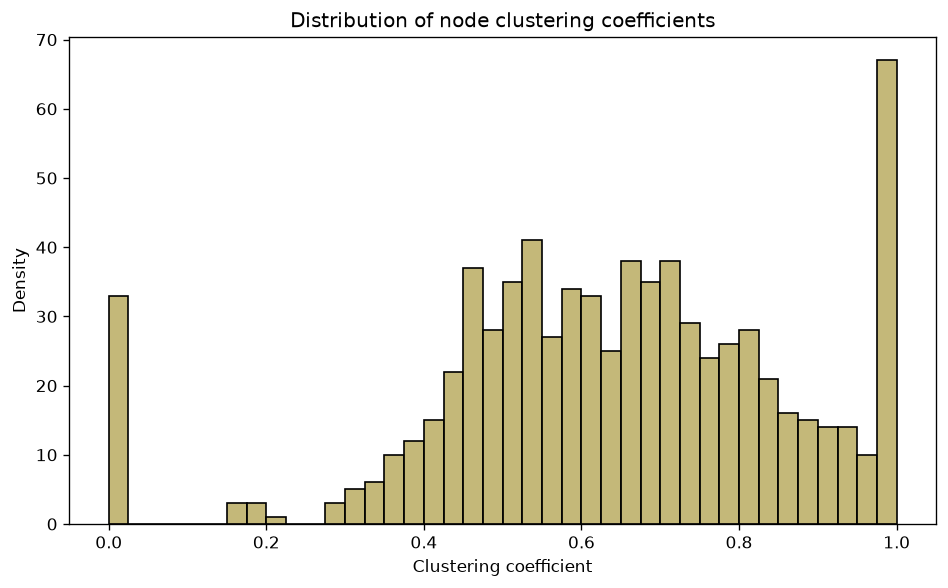

In [441]:
cc = np.asarray(list(clustering_coefficients.values()))

fig, ax = plt.subplots(figsize=(8, 5), dpi=120)

sns.histplot(
    cc,
    bins=40,
    stat="count",
    color="#B0A14C",
    ax=ax,
)

ax.set_title("Distribution of node clustering coefficients")
ax.set_xlabel("Clustering coefficient")
ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

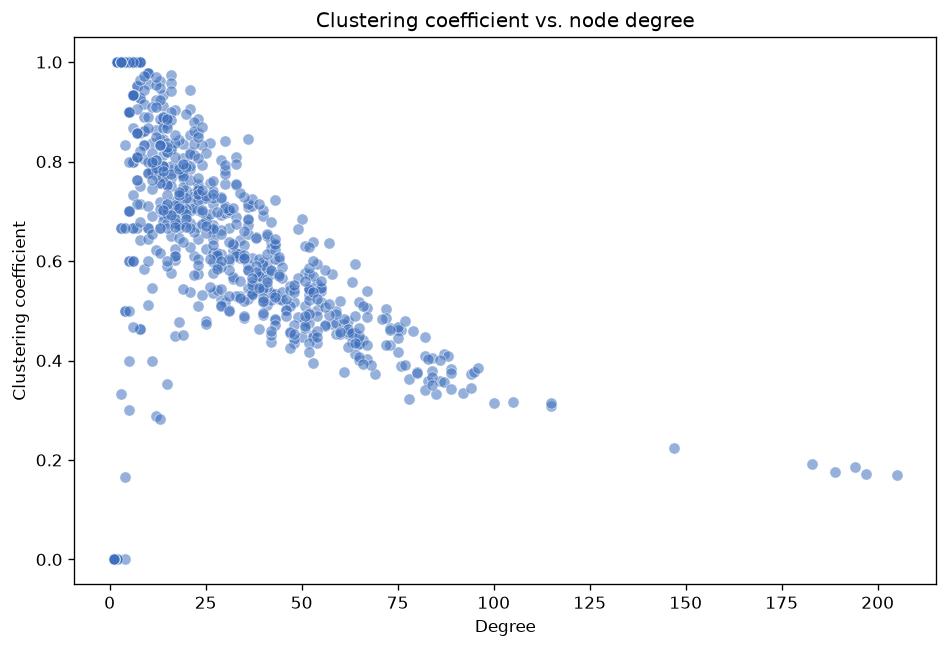

In [442]:
nodes = list(gcc.nodes)

deg = np.array([gcc.degree(n) for n in nodes])
cc = np.array([clustering_coefficients[n] for n in nodes])

df = pd.DataFrame({"degree": deg, "clustering": cc})

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=120)

sns.scatterplot(
    data=df, x="degree", y="clustering",
    s=45, alpha=0.55, color="#3E6FBD", edgecolor="white", linewidth=0.5,
    ax=ax,
)

ax.set_title("Clustering coefficient vs. node degree")
ax.set_xlabel("Degree")
ax.set_ylabel("Clustering coefficient")

plt.tight_layout()
plt.show()

### 1.2. Path length

- Calculate the average length of the shortest path between two vertices of the graph

- Plot a histogram of the dependence of the average length of the shortest path on the degree of the vertex

In [443]:
avg_shortest_path

3.0968329646572026

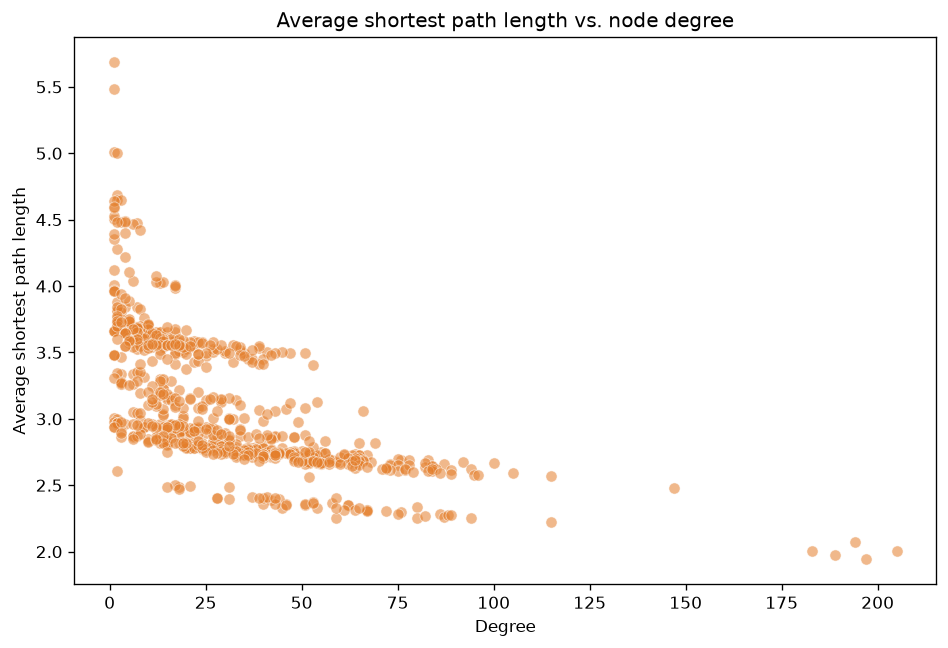

In [444]:
nodes = list(gcc.nodes)

distances = [nx.single_source_shortest_path_length(gcc, n) for n in nodes]
avg_shortest_path_lengths = [sum(d.values()) / (len(d) - 1) for d in distances]

degrees = [gcc.degree(n) for n in nodes]

df = pd.DataFrame({"degree": deg, "avg_shortest_path": avg_shortest_path_lengths})

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=120)

sns.scatterplot(
    data=df, x="degree", y="avg_shortest_path",
    s=45, alpha=0.55, color="#E47F2C", edgecolor="white", linewidth=0.5,
    ax=ax,
)

ax.set_title("Average shortest path length vs. node degree")
ax.set_xlabel("Degree")
ax.set_ylabel("Average shortest path length")

plt.tight_layout()
plt.show()

### 1.3. Distribution of node degrees

- What is the distribution of node degrees? Run goodness-of-fit test and estimate parameters of the distribution.

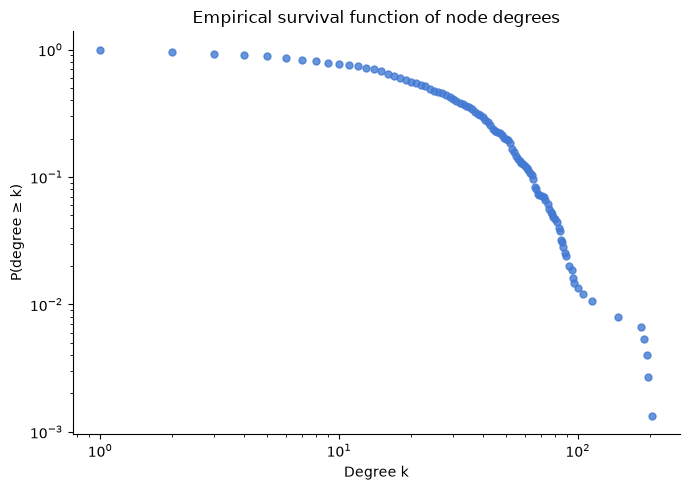

In [445]:
deg = np.array([d for _, d in gcc.degree()])
deg = deg[deg > 0]

values, counts = np.unique(deg, return_counts=True)
S = counts[::-1].cumsum()[::-1] / deg.size

fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(values, S, "o", markersize=5, color="#4279D3", alpha=0.8)
ax.set_xlabel("Degree k")
ax.set_ylabel("P(degree ≥ k)")
ax.set_title("Empirical survival function of node degrees")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

#### Clauset-Shalizi-Newman Test

In [446]:
fit = powerlaw.Fit(deg, discrete=True)

xmin = fit.xmin
alpha = fit.alpha

print(f"Estimated xmin: {xmin}")
print(f"Estimated alpha: {alpha}")

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 97/97 [00:00<00:00, 1410.24it/s]

Estimated xmin: 32.0
Estimated alpha: 2.977719459706919


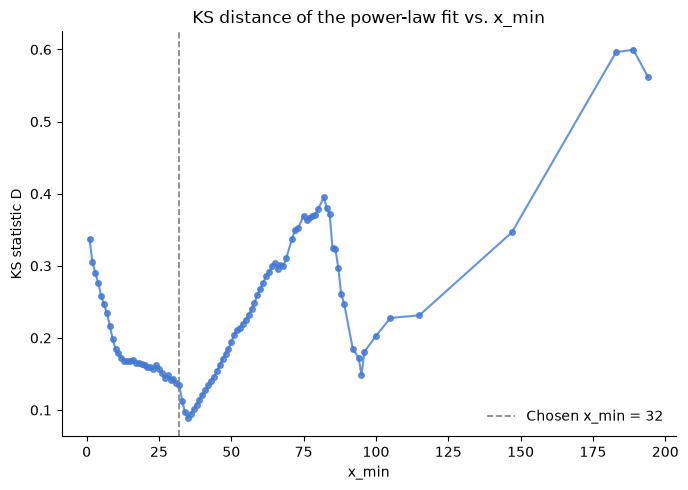

In [447]:
res = fit.xmin_fitting_results

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(res["xmins"], res["distances"], "o-", markersize=4, color="#4279D3", alpha=0.8)
ax.axvline(xmin, color="gray", ls="--", lw=1.2, label=f"Chosen x_min = {xmin:.0f}")

ax.set_xlabel("x_min")
ax.set_ylabel("KS statistic D")
ax.set_title("KS distance of the power-law fit vs. x_min")
ax.legend(frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [448]:
q = (deg >= xmin).sum() / deg.size

def bootstrap_sampling(deg, q, xmin, alpha):
    if np.random.rand() < q:
        uniform = np.random.uniform(0, 1)
        return xmin * (1 - uniform) ** (-1 / (alpha - 1))
    else:
        return np.random.choice(deg[deg < xmin])

def bootstrap_powerlaw_fit(deg, num_bootstrap=1000):
    bootstrap_alphas = []
    bootstrap_xmins = []
    bootstrap_D = []

    for _ in tqdm(range(num_bootstrap)):
        bootstrap_sample = np.array([bootstrap_sampling(deg, q, xmin, alpha) for _ in range(len(deg))])
        fit = powerlaw.Fit(bootstrap_sample, discrete=True, verbose=False)
        bootstrap_alphas.append(fit.alpha)
        bootstrap_xmins.append(fit.xmin)
        bootstrap_D.append(fit.D)

    return np.array(bootstrap_alphas), np.array(bootstrap_xmins), np.array(bootstrap_D)

def powerlaw_hypothesis_test(deg, num_bootstrap=1000):
    fit = powerlaw.Fit(deg, discrete=True, verbose=False)
    original_D = fit.D

    bootstrap_alphas, bootstrap_xmins, bootstrap_D = bootstrap_powerlaw_fit(deg, num_bootstrap)

    p_value = (1 + np.sum(bootstrap_D >= original_D)) / (num_bootstrap + 1)

    return p_value

In [449]:
p_value = powerlaw_hypothesis_test(deg, num_bootstrap=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [450]:
print(f"p-value: {p_value:.4f}")
print(f"H0: The degree distribution follows a power-law distribution - {p_value > 0.1}")

p-value: 0.0010
H0: The degree distribution follows a power-law distribution - False


#### Compare with other distributions

##### Lognormal

In [451]:
lognormal_mu, lognormal_sigma, lognormal_D = fit.lognormal.mu, fit.lognormal.sigma, fit.lognormal.D

print(f"Lognormal fit - mu: {lognormal_mu:.4f}, sigma: {lognormal_sigma:.4f}, D: {lognormal_D:.4f}")

Lognormal fit - mu: 3.6935, sigma: 0.5053, D: 0.0359


In [452]:
R, p = fit.distribution_compare("power_law", "lognormal")

print(f"Distribution comparison (power-law vs lognormal) - R: {R:.4f}, p-value: {p:.4f}")
print(f"Better fit: {'power-law' if R > 0 else 'lognormal'}")

Distribution comparison (power-law vs lognormal) - R: -24.2682, p-value: 0.0003
Better fit: lognormal


##### Exopnential

In [453]:
expon_lambda, expon_D = fit.exponential.Lambda, fit.exponential.D

print(f"Exponential fit - lambda: {expon_lambda:.4f}, D: {expon_D:.4f}")

Exponential fit - lambda: 0.0408, D: 0.0517


In [454]:
R, p = fit.distribution_compare("lognormal", "exponential")

print(f"Distribution comparison (lognormal vs exponential) - R: {R:.4f}, p-value: {p:.4f}")
print(f"Better fit: {'lognormal' if R > 0 else 'exponential'}")

Distribution comparison (lognormal vs exponential) - R: 3.4458, p-value: 0.0187
Better fit: lognormal


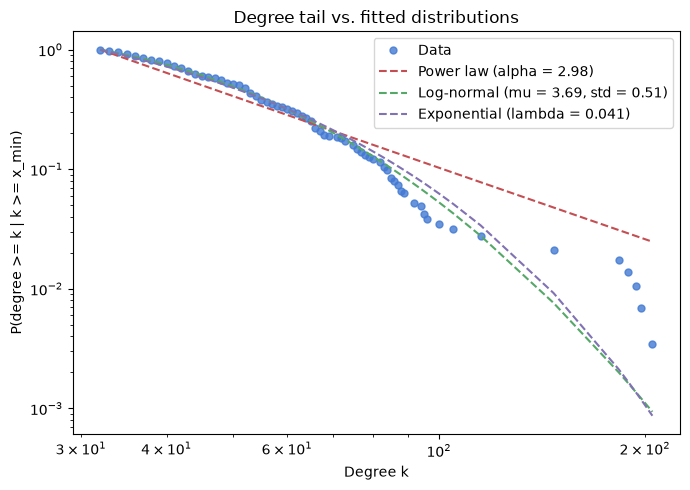

In [455]:
fig, ax = plt.subplots(figsize=(7, 5))

fit.plot_ccdf(ax=ax, linestyle="none", marker="o", markersize=5, color="#4279D3", alpha=0.8, label="Data")
fit.power_law.plot_ccdf(ax=ax, color="#C44E52", ls="--", label=f"Power law (alpha = {fit.alpha:.2f})")
fit.lognormal.plot_ccdf(ax=ax, color="#55A868", ls="--", label=f"Log-normal (mu = {lognormal_mu:.2f}, std = {lognormal_sigma:.2f})")
fit.exponential.plot_ccdf(ax=ax, color="#8172B3", ls="--", label=f"Exponential (lambda = {expon_lambda:.3f})")

ax.set_xlabel("Degree k")
ax.set_ylabel("P(degree >= k | k >= x_min)")
ax.set_title("Degree tail vs. fitted distributions")
ax.legend()

plt.tight_layout()
plt.show()

#### Results

The tail of the degrees distribution seems to followe a lognormal law. That doesn't necessarily mean that it is not a complex network, rather that it might not be a scale-free one. And we should take into account the finite nature of our discrete sample. 

### 1.4. Determine which are the most important and significant neurons in our brain?

In [456]:
degree_centrality = nx.degree_centrality(gcc)
betweenness_centrality = nx.betweenness_centrality(gcc)
closeness_centrality = nx.closeness_centrality(gcc)

In [457]:
def plot_centrality_distribution(centrality_dict):
    score = pd.Series(centrality_dict)
    span = score.max() - score.min()
    s = (score - score.min()) / span if span > 0 else score * 0

    cmap = plt.get_cmap("Reds")

    def to_rgb(c):
        return f"rgb({int(c[0] * 255)}, {int(c[1] * 255)}, {int(c[2] * 255)})"

    node_sizes = [2 + 13 * s[n] ** 2 for n in gcc.nodes()]
    node_colors = [to_rgb(cmap(0.15 + 0.85 * s[n])) for n in gcc.nodes()]

    plot_connectome(gcc, node_colors=node_colors, node_sizes=node_sizes, show_legend=False)
    

def print_top_neurons(centrality_dict, k=5):
    ranked = sorted(gcc.nodes(), key=lambda n: centrality_dict[n], reverse=True)

    seen = set()
    for n in ranked:
        region, name, hemisphere, function = get_neuron_info(gcc.nodes[n])

        label = name if name.startswith(("Left-", "Right-")) else f"{name} ({hemisphere.lower()})"
        if label in seen:
            continue
        seen.add(label)

        description = "Responsible for " + function

        print(f"{len(seen)}. {label}: {description}  [centrality = {centrality_dict[n]:.4f}]")

        if len(seen) == k:
            break

#### Betweenness Centrality

In [458]:
plot_centrality_distribution(betweenness_centrality)
print_top_neurons(betweenness_centrality, k=5)

1. Left-thalamus-proper: Responsible for Transmission of sensory signals to the cortex  [centrality = 0.2421]
2. Right-thalamus-proper: Responsible for Transmission of sensory signals to the cortex  [centrality = 0.1801]
3. Left-caudate: Responsible for Movement control, training  [centrality = 0.1464]
4. Right-caudate: Responsible for Movement control, training  [centrality = 0.1422]
5. Right-putamen: Responsible for Movement, skill formation  [centrality = 0.0727]


#### Degree Centrality

In [459]:
plot_centrality_distribution(degree_centrality)
print_top_neurons(degree_centrality, k=5)

1. Right-caudate: Responsible for Movement control, training  [centrality = 0.2744]
2. Left-thalamus-proper: Responsible for Transmission of sensory signals to the cortex  [centrality = 0.2637]
3. Right-putamen: Responsible for Movement, skill formation  [centrality = 0.2597]
4. Right-thalamus-proper: Responsible for Transmission of sensory signals to the cortex  [centrality = 0.2530]
5. Left-caudate: Responsible for Movement control, training  [centrality = 0.2450]


#### Closeness Centrality

In [460]:
plot_centrality_distribution(closeness_centrality)
print_top_neurons(closeness_centrality, k=5)

1. Left-thalamus-proper: Responsible for Transmission of sensory signals to the cortex  [centrality = 0.5152]
2. Right-thalamus-proper: Responsible for Transmission of sensory signals to the cortex  [centrality = 0.5064]
3. Left-caudate: Responsible for Movement control, training  [centrality = 0.4993]
4. Right-caudate: Responsible for Movement control, training  [centrality = 0.4990]
5. Right-putamen: Responsible for Movement, skill formation  [centrality = 0.4816]


#### Results

Independent of how you define teh importance, it seems that both Thalami-proper and both Caudetes play an important role in our brain. It does make sense since managing snesory signals and controlling movement is needed pretty much in any activity.

### 1.5. Is the human brain a complex network? Why?

For a network to be complex, 4 properties generally hold:
1. Small World - The average shortest distance is approximately $O(\log N)$, that is small wrt the size of the network. Our average shortest path length was about 3, high clustering coefficient (~0.5) also supports the high traversability between the nodes.
2. Hubs - Nodes of extremely high degree exist. Mean degree is 30, the maximum - ~200
3. Giant Component - One connected component holding a majority of nodes. Our GCC has 748 out of 1015 noeds total.
4. Power Law - Main characteristics follow a Power Law Distribution.

We have evidence of properties 1-3 holding for the human brain connectome yet we couldn't acquire strong evidence of the power law distribution. This could be attributed to the scale at which we had to work with.

In any case, I would say that the brain is a complex network at large as it exhibits most of the properties typically found in complex networks.

## Problem 2. Labeling of the brain connectome (30 points)

- Create an automatic labeling of the brain's connectome. Labeling refers to the division of connections into a number of groups, and the assignment of each vertex to one of these groups.

- Try several different labeling algorithms and describe how you chose the values for their parameters.

- Compare the results of the different algorithms to each other and to the original labeling.

In [461]:
def plot_communities(communities, show_legend=True):
    communities = sorted((set(c) for c in communities), key=len, reverse=True)
    membership = {node: i for i, c in enumerate(communities, start=1) for node in c}

    node_colors = get_node_colors([membership[n] for n in gcc.nodes()])
    plot_connectome(gcc, node_colors=node_colors, show_legend=show_legend)

In [462]:
def community_composition(communities, top=5):
    for i, c in enumerate(communities, start=1):
        infos = [get_neuron_info(gcc.nodes[n]) for n in c]
        areas = pd.Series([info[1] for info in infos]).value_counts()
        hemi = pd.Series([info[2] for info in infos]).value_counts(normalize=True)

        hemi_text = ", ".join(f"{h} {p:.0%}" for h, p in hemi.items())
        listed = ",\n\t".join(f"{a} ({k})" for a, k in areas.head(top).items())

        print(f"Community {i}: {len(c)} nodes ({hemi_text})")
        print(f"\t{listed}\n")

### Label propagation

In [463]:
label_propagation = nx.community.asyn_lpa_communities(gcc)
label_propagation = sorted((set(c) for c in label_propagation), key=len, reverse=True)

print(f"N Communities: {len(label_propagation)}")
print(f"Sizes: {[len(c) for c in label_propagation]}")
print(f"Modularity: {nx.community.modularity(gcc, label_propagation):.4f}")

N Communities: 10
Sizes: [212, 190, 178, 63, 50, 47, 2, 2, 2, 2]
Modularity: 0.5901


In [464]:
community_composition(label_propagation)

Community 1: 212 nodes (Left 100%, Right 0%)
	Superiorparietal (29),
	Inferiorparietal (22),
	Precuneus (21),
	Supramarginal (16),
	Lateraloccipital (16)

Community 2: 190 nodes (Right 100%)
	Superiorparietal (28),
	Inferiorparietal (25),
	Precuneus (23),
	Lateraloccipital (21),
	Lingual (14)

Community 3: 178 nodes (Right 100%)
	Superiorfrontal (38),
	Precentral (36),
	Postcentral (20),
	Rostralmiddlefrontal (15),
	Paracentral (12)

Community 4: 63 nodes (Left 100%)
	Superiorfrontal (34),
	Rostralmiddlefrontal (14),
	Caudalanteriorcingulate (5),
	Caudalmiddlefrontal (4),
	Rostralanteriorcingulate (2)

Community 5: 50 nodes (Left 100%)
	Postcentral (16),
	Precentral (15),
	Parsopercularis (10),
	Supramarginal (5),
	Parstriangularis (2)

Community 6: 47 nodes (Left 100%)
	Precentral (15),
	Superiorfrontal (9),
	Caudalmiddlefrontal (9),
	Paracentral (9),
	Postcentral (3)

Community 7: 2 nodes (Right 100%)
	Superiorfrontal (1),
	Rostralmiddlefrontal (1)

Community 8: 2 nodes (Right 100%)


In [465]:
plot_communities(label_propagation, show_legend=True)

### Louvain Algorithm

In [466]:
louvain = nx.community.louvain_communities(gcc)
louvain = sorted((set(c) for c in louvain), key=len, reverse=True)

print(f"N Communities: {len(louvain)}")
print(f"Sizes: {[len(c) for c in louvain]}")
print(f"Modularity: {nx.community.modularity(gcc, louvain):.4f}")

N Communities: 5
Sizes: [189, 186, 184, 108, 81]
Modularity: 0.6232


In [467]:
community_composition(louvain)

Community 1: 189 nodes (Right 100%)
	Superiorfrontal (39),
	Precentral (36),
	Postcentral (28),
	Rostralmiddlefrontal (16),
	Paracentral (12)

Community 2: 186 nodes (Left 100%)
	Superiorparietal (26),
	Inferiorparietal (22),
	Precuneus (20),
	Lateraloccipital (16),
	Lingual (15)

Community 3: 184 nodes (Left 100%)
	Superiorfrontal (43),
	Precentral (31),
	Postcentral (22),
	Rostralmiddlefrontal (17),
	Caudalmiddlefrontal (13)

Community 4: 108 nodes (Right 99%, Left 1%)
	Superiorparietal (22),
	Precuneus (22),
	Inferiorparietal (21),
	Supramarginal (9),
	Isthmuscingulate (6)

Community 5: 81 nodes (Right 100%)
	Lateraloccipital (21),
	Lingual (14),
	Fusiform (9),
	Pericalcarine (8),
	Cuneus (8)



In [468]:
plot_communities(louvain, show_legend=True)

### Girvan-Newman Algorithm

Girvan-Newman is an exopensive algorithm, each time having to calculate edge betweenness multiple times over the entire graph before making a successful split. We'll estimate edge betweenness on a random subsample of the graph. The higher the "k" parameter - the more precise our estimation gets

In [469]:
def approx_most_central_edge(H, k=200):
    eb = nx.edge_betweenness_centrality(H, k=min(k, len(H)))
    return max(eb, key=eb.get)

gn = nx.community.girvan_newman(gcc, most_valuable_edge=approx_most_central_edge)

best, best_q = None, -1
qs = []
comm_lens = []
for comms in itertools.islice(gn, 0, 30):
    q = nx.community.modularity(gcc, comms)
    qs.append(q)
    comm_lens.append(len(comms))

    if q > best_q:
        best, best_q = comms, q

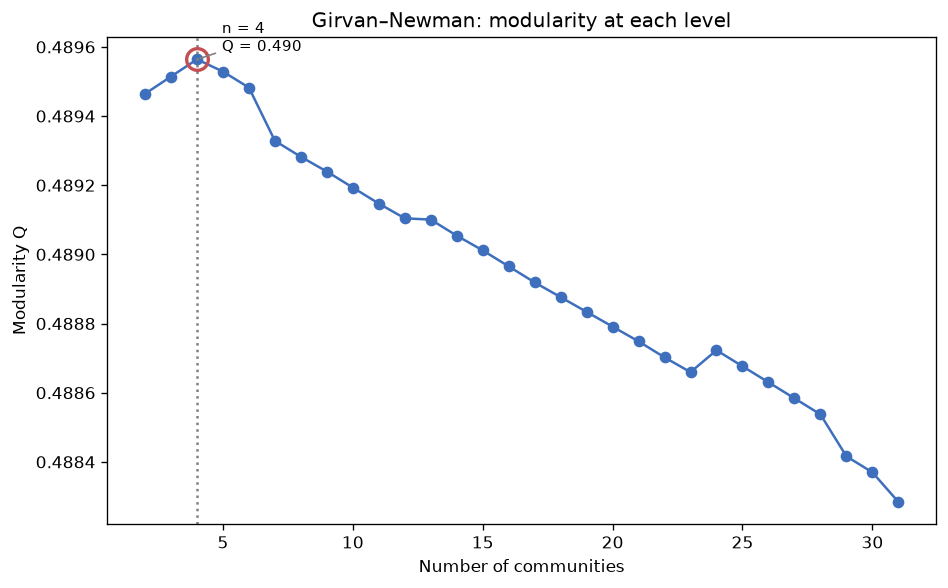

In [470]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)

ax.plot(comm_lens, qs, "-o", color="#3E6FBD")

ax.axvline(len(best), color="gray", ls=":")
ax.plot(len(best), best_q, "o", ms=13, mfc="none", mec="#C44E52", mew=2)
ax.annotate(
    f"n = {len(best)}\nQ = {best_q:.3f}",
    xy=(len(best), best_q), xytext=(15, 5), textcoords="offset points",
    fontsize=9, arrowprops=dict(arrowstyle="-", color="gray", lw=1),
)

ax.set_title("Girvan–Newman: modularity at each level")
ax.set_xlabel("Number of communities")
ax.set_ylabel("Modularity Q")

plt.tight_layout()
plt.show()

In [471]:
community_composition(best)

Community 1: 373 nodes (Right 100%, Left 0%)
	Superiorfrontal (38),
	Precentral (36),
	Superiorparietal (29),
	Postcentral (28),
	Inferiorparietal (25)

Community 2: 2 nodes (Right 100%)
	Superiorfrontal (1),
	Rostralmiddlefrontal (1)

Community 3: 2 nodes (Right 100%)
	Superiortemporal (1),
	Transversetemporal (1)

Community 4: 371 nodes (Left 100%, Right 0%)
	Superiorfrontal (43),
	Precentral (31),
	Superiorparietal (29),
	Postcentral (25),
	Inferiorparietal (22)



In [472]:
plot_communities(best, show_legend=True)

### Comparison

In [473]:
results = pd.DataFrame({"label_propagation": 
              {"modularity": nx.community.modularity(gcc, label_propagation), 
               "n_communities": len(label_propagation)},
              "louvain":
              {"modularity": nx.community.modularity(gcc, louvain), 
               "n_communities": len(louvain)},
              "girvan_newman":  
              {"modularity": nx.community.modularity(gcc, best), 
               "n_communities": len(best)}}).T

results

,modularity,n_communities
label_propagation,0.590103,10.0
louvain,0.623193,5.0
girvan_newman,0.489564,4.0


## Problem 3. Assortativity (15 points)

- Рассмотрите:
  - Коннектом целиком
  - Различные области, найденные с помощью автоматической разметки, по отдельности
- Посчитайте для них ассортативность, постройте необходимые графики
- Проанализируйте результаты
- Consider:
  - Connect as a whole
  - Various areas found using automatic labeing individually
- Calculate the assortativity for them, plot the necessary graphs
- Analyze the results

### Degree Correlation

In [474]:
r = nx.degree_assortativity_coefficient(gcc)
print(f"Global Assortativity Coefficient: {r:4f}")

Global Assortativity Coefficient: -0.023609


In [475]:
for i, c in enumerate(louvain):
    r = nx.degree_assortativity_coefficient(gcc.subgraph(c))
    print(f"Louvain Community {i} Assortativity Coefficient: {r:4f}\n")

Louvain Community 0 Assortativity Coefficient: -0.073698

Louvain Community 1 Assortativity Coefficient: -0.018751

Louvain Community 2 Assortativity Coefficient: -0.000091

Louvain Community 3 Assortativity Coefficient: -0.169756

Louvain Community 4 Assortativity Coefficient: -0.068220



### Average Nearest-Neighbor Degree

In [476]:
def plot_knn(df, k_nn_by_deg):
    k = df["degree"].to_numpy()
    neutral = (k ** 2).mean() / k.mean()

    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=120)

    ax.scatter(
        k_nn_by_deg.index, k_nn_by_deg["avg_nn_degree"],
        color="#3E6FBD", alpha=0.5,
        label="Mean per degree value",
    )

    ax.axhline(neutral, color="gray", ls="--", lw=1.2,
            label=f"Baseline (No Correlation)")

    ax.set_xlabel("Degree k")
    ax.set_ylabel("Average neighbour degree  $k_{nn}(k)$")
    ax.set_title("Average neighbour degree vs. degree")

    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()

#### Global

In [477]:
avg_degree = nx.average_neighbor_degree(gcc)
degree = nx.degree(gcc)

df = pd.DataFrame({"degree": dict(degree), "avg_nn_degree": avg_degree})
k_nn_by_deg = df.groupby("degree").mean()

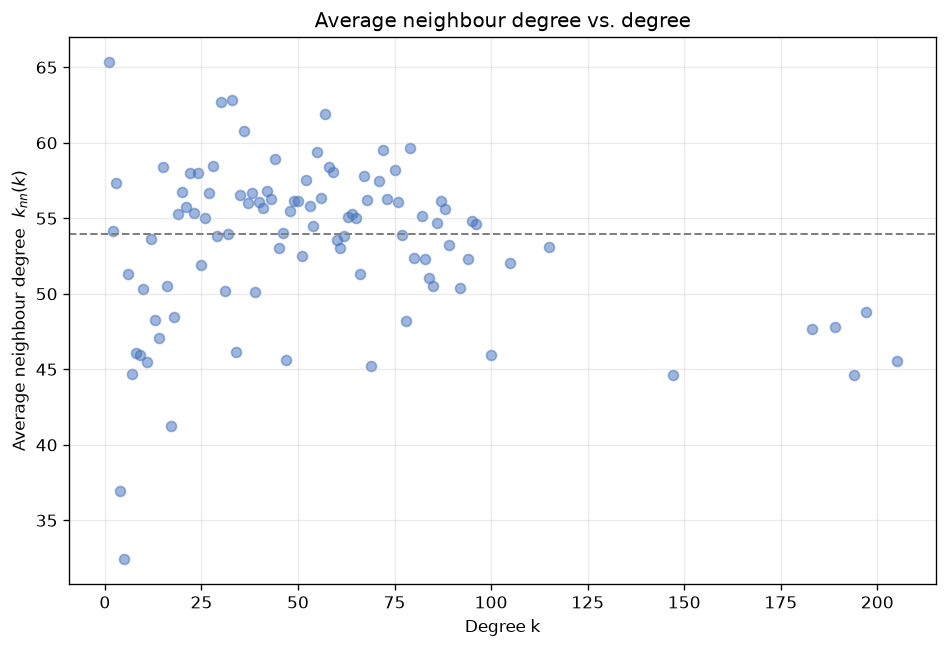

In [478]:
plot_knn(df, k_nn_by_deg)

#### Louvain

In [479]:
def get_knn(G):
    avg_degree = nx.average_neighbor_degree(G)
    degree = nx.degree(G)

    df = pd.DataFrame({"degree": dict(degree), "avg_nn_degree": avg_degree})
    k_nn_by_deg = df.groupby("degree").mean()

    return df, k_nn_by_deg

In [480]:
knn_data = [get_knn(gcc.subgraph(c)) for c in louvain]

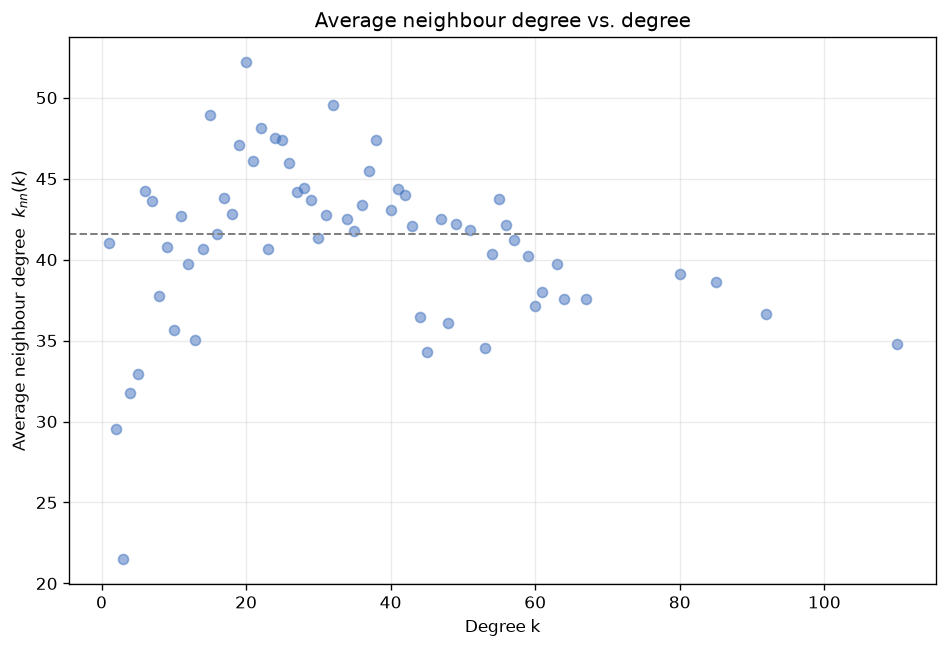

In [481]:
plot_knn(*knn_data[0])

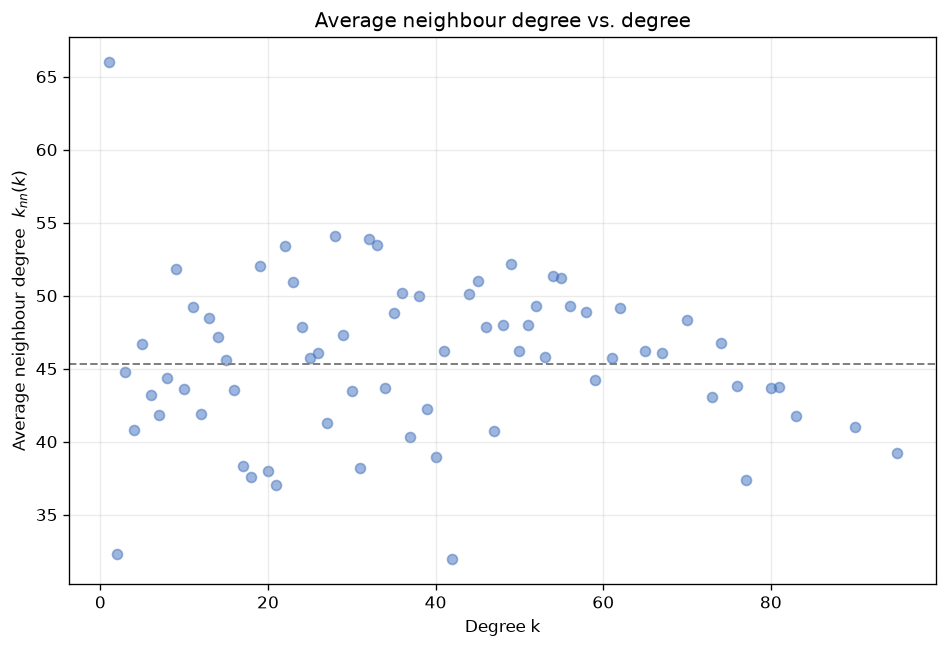

In [482]:
plot_knn(*knn_data[1])

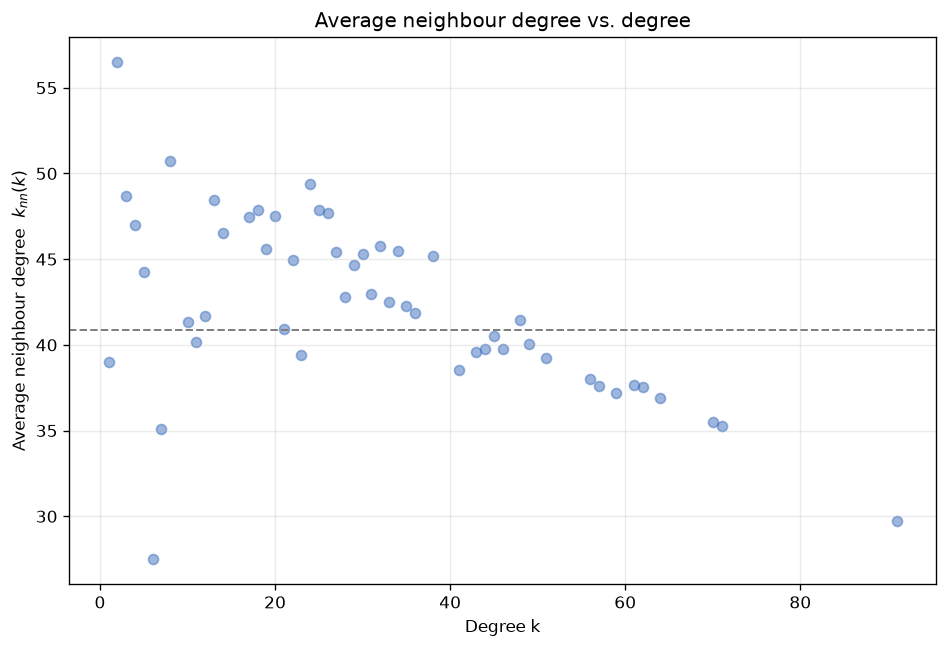

In [483]:
plot_knn(*knn_data[3])

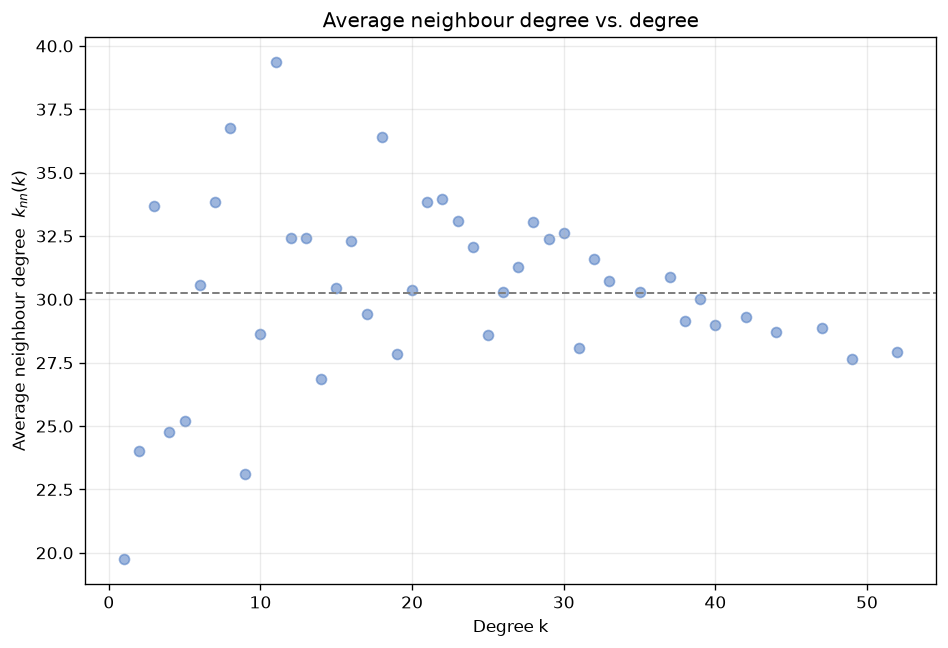

In [484]:
plot_knn(*knn_data[4])

### Rich Club Coefficient

In [485]:
def plot_rich_coeffs(rc_coeff):
    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=120)

    ax.plot(
        rc_coeff.keys(), rc_coeff.values(),
        color="#3E6FBD", alpha=0.5
    )

    ax.set_xlabel("Degree k")
    ax.set_ylabel("Rich-club coefficient  $\\phi(k)$")
    ax.set_title("Rich-club coefficient vs. degree")

    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()

#### Global

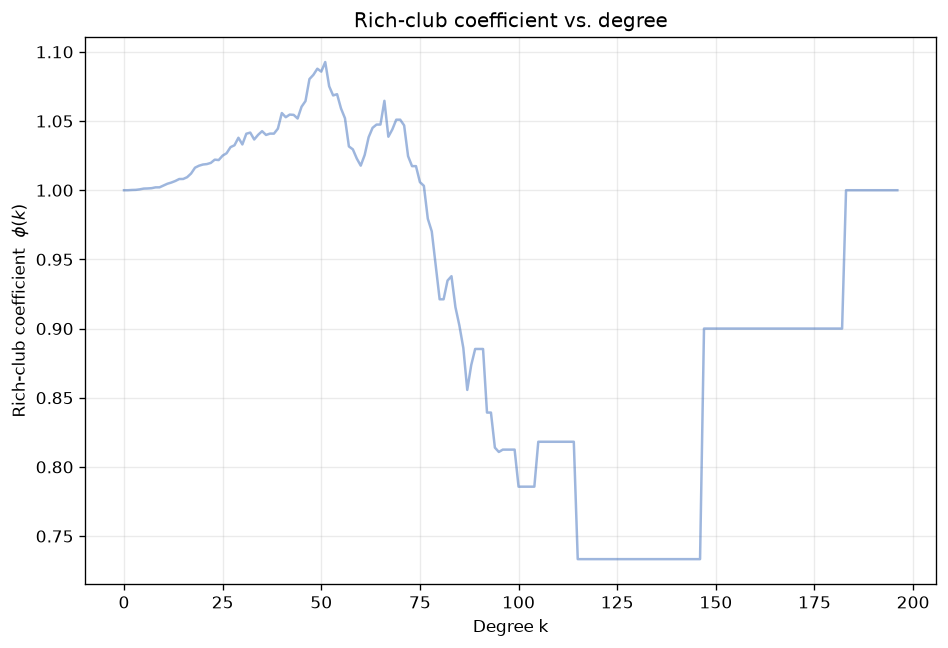

In [486]:
rc_coeffs = nx.rich_club_coefficient(gcc, normalized=True)
plot_rich_coeffs(rc_coeffs)

#### Louvain

In [487]:
rc_coeffs = [nx.rich_club_coefficient(gcc.subgraph(c), normalized=True) for c in louvain]

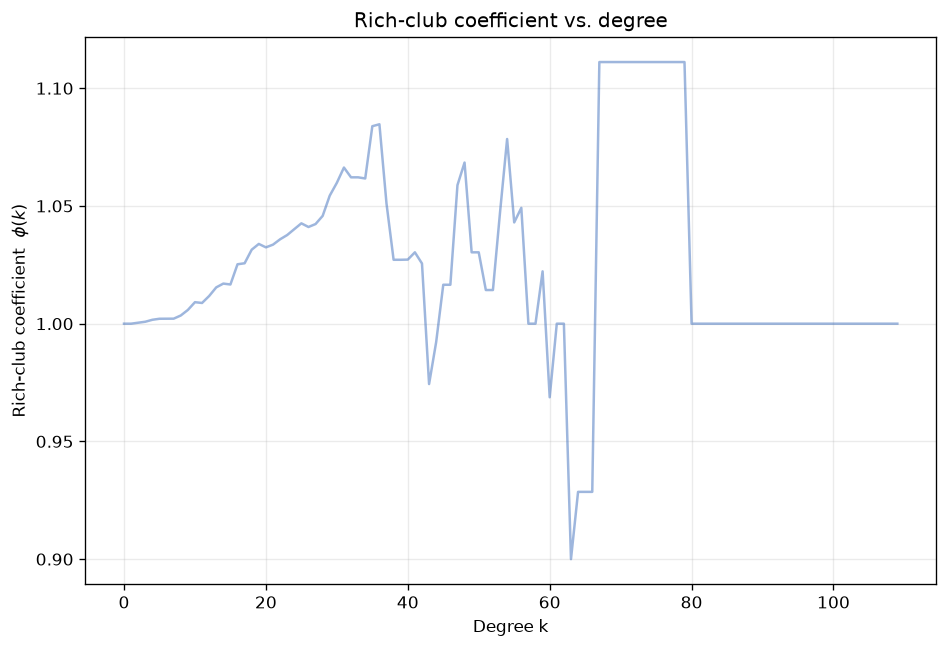

In [488]:
plot_rich_coeffs(rc_coeffs[0])

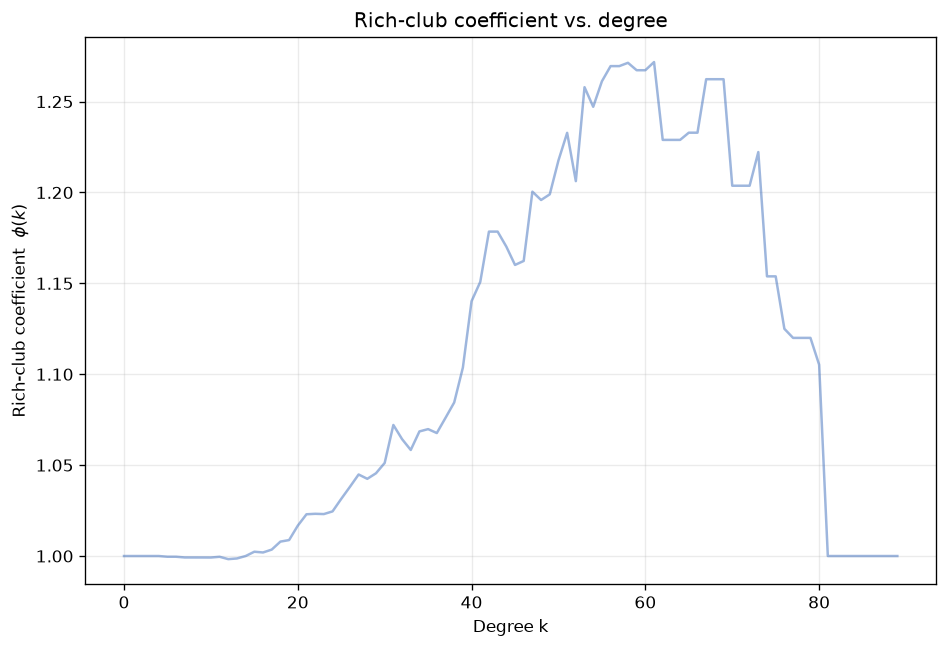

In [489]:
plot_rich_coeffs(rc_coeffs[1])

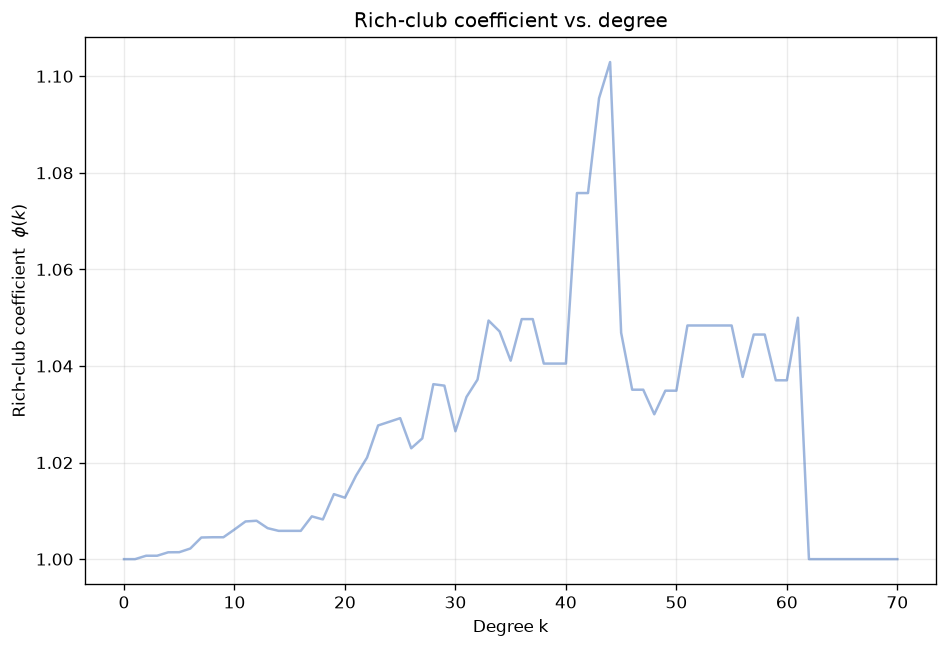

In [490]:
plot_rich_coeffs(rc_coeffs[3])

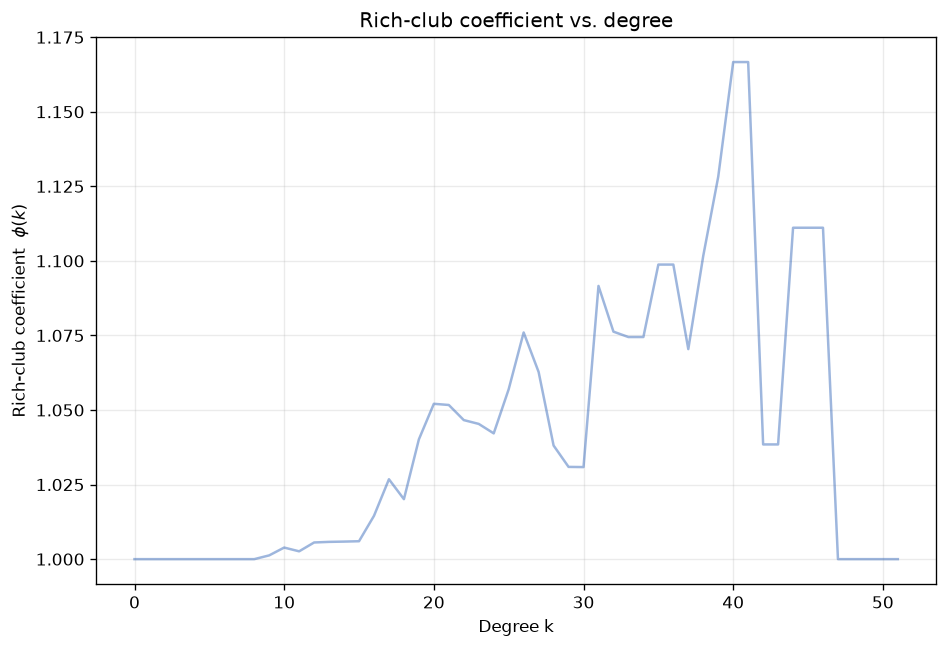

In [491]:
plot_rich_coeffs(rc_coeffs[4])

### Results

All approaches to determining the assortativity show weak proof of the existence of any discernable behavior. It seems that the whole connectome is large doesn't have any specific tendency when it comes to degree correlation. 

Same goes for all communities found by Louvain algorithm except for maybe the 3rd one, this one shows mild signs of dissasortativity:
- A negative asssortativity coefficient (-0.15)
- A negative K-nn dependency on the degree (slightly negative slope)
- Weak evidence of rich clubs

## Problem 4. Transcranial magnetic stimulation (30 points)

__[Transcranial magnetic stimulation (TMS)](https://en.wikipedia.org/wiki/Transcranial_magnetic_stimulation)__ - a method that allows noninvasively stimulating the cerebral cortex. It is used for the rehabilitation of patients (for example, with motor disorders), and for the treatment of various diseases: Parkinson's disease, epilepsy, depression, schizophrenia, and others.

We would like to suggest that you conduct a TMS on your "patient". For this, you will need:

- "Weigh" the edges of the graph. For example, using some metric that decreases with increasing distance between vertices.

- Apply TMS to different areas of the brain. See how far the signal will spread, which areas it will affect, and what functions these areas are responsible for.

  Various methods can be used to implement signal propagation: `message passing', `random walk', `heat diffusion' and others.

  Try different methods (two or more), compare the results.

---

To determine which areas of the brain should be targeted with TMS, you can refer to scientific articles. For example: 

__[Evidence-based guidelines on the therapeutic use of repetitive transcranial magnetic stimulation (rTMS)](https://www.sciencedirect.com/science/article/pii/S1388245719312799?via%3Dihub)__. 

This article contains many studies that stimulated various areas of the brain using TMS. It also describes the symptoms of patients and the results of TMS use.

---

For example, in the picture below you can see:

- The patient's symptom is a motor disorder of the hand as a result of stroke.

- The area of application of TMS is the M1 zone. You can use a __[map of brain regions](https://atlas.brain-map.org/atlas?atlas=265297126)__ to orient yourself in the areas of a brain.

- The result of the therapy is an improvement in the patient's motor functions.

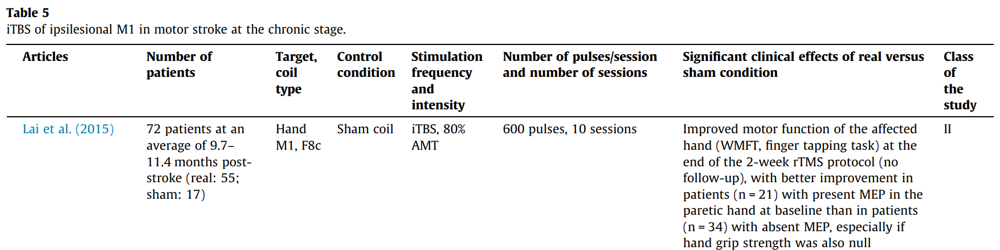

---

Good luck!

We'll assign exponential weights to each edge based on the mean fiber length. The reason for the exponential weighing is that it's naturally bounded by 1 and we can tune the parameter that would basically decide the locality of the spread.

In [492]:
nodes = list(gcc.nodes())

D = nx.to_numpy_array(gcc, nodelist=nodes, weight="fiber_length_mean", nonedge=np.inf)

lam = 1 / np.median(D[np.isfinite(D)])
W = np.exp(-lam * D)

In [493]:
node_info = [get_neuron_info(gcc.nodes[n]) for n in nodes]


def simulate(area, weights, func, hemisphere=None, baseline=False, rel_cut=0.05, **kwargs):
    stimulated = np.array([
        name == area and (hemisphere is None or hemi == hemisphere)
        for _, name, hemi, _ in node_info
    ], dtype=float)
    if not stimulated.any():
        raise ValueError(f"No nodes found for area {area!r}, hemisphere {hemisphere!r}")

    x, history = func(weights, stimulated, **kwargs)

    if len(history) > 1:
        h = history[1:]
        if baseline:
            pi = weights.sum(axis=1) / weights.sum()
            h = h / pi
        peak = h.max(axis=0)
    else:
        peak = np.zeros(len(nodes))

    df = pd.DataFrame(node_info, columns=["region", "area", "hemisphere", "function"])
    df["peak"] = peak
    df = df[df["peak"] > rel_cut * df["peak"].max()]

    return (
        df.groupby(["area", "hemisphere", "function"], as_index=False)
          .agg(nodes_reached=("peak", "size"), peak=("peak", "max"))
          .sort_values("peak", ascending=False, ignore_index=True)
          .round({"peak": 4})
    )

### Message Passing

In [494]:
def message_passing(weights, starting_vector, T=20, alpha=0.8, thr=0.02):
    P = weights / weights.sum(axis=1)[:, None]
    x = starting_vector.copy()
    history = [x.copy()]
    for _ in range(T):
        x = alpha * (P.T @ x)
        x = np.where(x < thr, 0, x)

        history.append(x.copy())

        if not x.any(): 
            break

    return x, np.array(history)

In [495]:
message_passing_result = simulate("Lateralorbitofrontal", W, message_passing, hemisphere="Right")

message_passing_result

,area,hemisphere,function,nodes_reached,peak
0,Right-putamen,Right,"Movement, skill formation",1,0.5806
1,Right-caudate,Right,"Movement control, training",1,0.4775
2,Insula,Right,"Body sensations, emotions, pain perception",4,0.1833
3,Right-pallidum,Right,"Movement, regulation of motor functions",1,0.1181
4,Right-thalamus-proper,Right,Transmission of sensory signals to the cortex,1,0.0661
5,Lateralorbitofrontal,Right,"Emotion control, decision-making",1,0.0377


###  Random Walk

In [496]:
def random_walk(weights, starting_vector, T=40, tol=1e-6):
    P = weights / weights.sum(axis=1)[:, None]

    pi = weights.sum(axis=1) / weights.sum()

    p = starting_vector / starting_vector.sum()
    history = [p.copy()]
    for _ in range(T):
        p = p @ P
        history.append(p.copy())

        if 0.5 * np.abs(p - pi).sum() < tol:
            print("converged")
            break

    return p, np.array(history)

In [497]:
random_walk_result = simulate("Lateralorbitofrontal", W, random_walk, hemisphere="Right", baseline=True)

random_walk_result

,area,hemisphere,function,nodes_reached,peak
0,Insula,Right,"Body sensations, emotions, pain perception",4,217.7173
1,Lateralorbitofrontal,Right,"Emotion control, decision-making",2,87.7742
2,Right-putamen,Right,"Movement, skill formation",1,75.5422
3,Rostralanteriorcingulate,Right,"Emotions, behavior control",1,47.4927
4,Right-caudate,Right,"Movement control, training",1,47.4927
5,Right-pallidum,Right,"Movement, regulation of motor functions",1,34.7462
6,Right-amygdala,Right,"Emotions, fear, aggression",1,33.1979
7,Caudalanteriorcingulate,Right,"Emotion control, decision-making",2,24.8925
8,Rostralmiddlefrontal,Right,"Planning, decision-making",1,17.8240


### Comparison of different areas

In [498]:
from plotly.subplots import make_subplots


def compare_results(result_a, result_b, k=10, names=("Message passing", "Random walk")):
    def areas(df):
        return set(zip(df["area"], df["hemisphere"]))

    def jaccard(a, b):
        return len(a & b) / len(a | b)

    def fmt(s):
        return ", ".join(f"{a} ({h})" for a, h in sorted(s)) or "-"

    top_a, top_b = areas(result_a.head(k)), areas(result_b.head(k))

    print(f"Jaccard, top {k}:       {jaccard(top_a, top_b):.3f}")
    print(f"Jaccard, all reached: {jaccard(areas(result_a), areas(result_b)):.3f}")
    print(f"Top {k} only in {names[0]}: {fmt(top_a - top_b)}")
    print(f"Top {k} only in {names[1]}: {fmt(top_b - top_a)}")


def plot_affected(result, area, hemisphere=None, show=True):
    peak = {(a, h): p for a, h, p in zip(result["area"], result["hemisphere"], result["peak"])}

    def is_stimulated(name, hemi):
        return name == area and (hemisphere is None or hemi == hemisphere)

    others = [p for (a, h), p in peak.items() if not is_stimulated(a, h)]
    top = max(others) if others else 1

    cmap = plt.get_cmap("Reds")
    colors, sizes = [], []
    for _, name, hemi, _ in node_info:
        if is_stimulated(name, hemi):
            colors.append("rgb(40, 100, 210)")
            sizes.append(8)
        elif (name, hemi) in peak:
            s = min(peak[(name, hemi)] / top, 1)
            c = cmap(0.35 + 0.65 * s)
            colors.append(f"rgb({int(c[0] * 255)}, {int(c[1] * 255)}, {int(c[2] * 255)})")
            sizes.append(3 + 7 * s)
        else:
            colors.append("rgba(190, 190, 190, 0.3)")
            sizes.append(2)

    return plot_connectome(gcc, node_colors=colors, node_sizes=sizes, show_legend=False, show=show)


def plot_affected_pair(result_a, result_b, area, hemisphere=None, titles=("Message passing", "Random walk")):
    combined = make_subplots(
        rows=1, cols=2,
        specs=[[{"type": "scene"}, {"type": "scene"}]],
        subplot_titles=titles, horizontal_spacing=0.02,
    )
    for col, result in enumerate((result_a, result_b), start=1):
        for trace in plot_affected(result, area, hemisphere, show=False).data:
            combined.add_trace(trace, row=1, col=col)

    combined.update_layout(width=1400, height=650, showlegend=False, margin=dict(l=0, r=0, t=40, b=0))
    combined.show()

#### Precentral Area

We expect the stimulation of precentral area to reach areas responsible for movement and pain perception. The stimulation of this region is usually used for motor recovery and pain relief

In [514]:
starting_area = "Precentral"
starting_hemisphere = "Left"

In [515]:
message_passing_result = simulate(starting_area, W, message_passing, hemisphere=starting_hemisphere)

print(f"Areas reached: {len(message_passing_result)}")
message_passing_result.head(10)

Areas reached: 17


,area,hemisphere,function,nodes_reached,peak
0,Precentral,Left,Movement control (motor cortex),31,1.2714
1,Postcentral,Left,"Sensory information, sense of touch",12,0.6939
2,Paracentral,Left,Control of leg and trunk movements,9,0.4246
3,Caudalmiddlefrontal,Left,"Planning, cognitive control",8,0.3513
4,Parsopercularis,Left,"Speech production, sound processing",4,0.3112
5,Insula,Left,"Body sensations, emotions, pain perception",5,0.2505
6,Left-putamen,Left,"Movement, skill formation",1,0.2475
7,Left-caudate,Left,"Movement control, training",1,0.2215
8,Supramarginal,Left,"Speech comprehension, sensorimotor integration",10,0.2105
9,Superiorfrontal,Left,"Attention control, motor planning",9,0.1903


In [516]:
random_walk_result = simulate(starting_area, W, random_walk, hemisphere=starting_hemisphere, baseline=True)

print(f"Areas reached: {len(random_walk_result)}")
random_walk_result.head(10)

Areas reached: 20


,area,hemisphere,function,nodes_reached,peak
0,Precentral,Left,Movement control (motor cortex),31,40.1344
1,Paracentral,Left,Control of leg and trunk movements,10,22.2324
2,Postcentral,Left,"Sensory information, sense of touch",25,16.7572
3,Parsopercularis,Left,"Speech production, sound processing",10,7.9344
4,Caudalmiddlefrontal,Left,"Planning, cognitive control",13,6.7090
5,Superiorfrontal,Left,"Attention control, motor planning",43,6.4875
6,Insula,Left,"Body sensations, emotions, pain perception",10,6.3547
7,Supramarginal,Left,"Speech comprehension, sensorimotor integration",13,5.8003
8,Parstriangularis,Left,"Speech processing, language comprehension",3,4.8576
9,Precuneus,Left,"Consciousness, self-awareness, attention",3,4.1521


In [517]:
compare_results(message_passing_result, random_walk_result)

Jaccard, top 10:       0.667
Jaccard, all reached: 0.762
Top 10 only in Message passing: Left-caudate (Left), Left-putamen (Left)
Top 10 only in Random walk: Parstriangularis (Left), Precuneus (Left)


In [518]:
plot_affected_pair(message_passing_result, random_walk_result, starting_area, starting_hemisphere)

The top stimulated areas reached by both algorithms are the same. Random walk reaches significanlty more areas, possibly due to the signal dying out in message passing. 

We see tha the main areas reached are responsible for movement control and sensory information and pain perception. This is the expected result.

#### Superior Temporal

This area is stimulated to affect auditorial hallucinations. We expect it to reach areas responsible for speech recognition

In [519]:
starting_area = "Superiortemporal"
starting_hemisphere = "Left"

In [520]:
message_passing_result = simulate(starting_area, W, message_passing, hemisphere=starting_hemisphere)

print(f"Areas reached: {len(message_passing_result)}")
message_passing_result.head(10)

Areas reached: 14


,area,hemisphere,function,nodes_reached,peak
0,Bankssts,Left,"Speech analysis, sound perception",4,0.5255
1,Superiortemporal,Left,Speech and sound processing,4,0.4245
2,Left-thalamus-proper,Left,Transmission of sensory signals to the cortex,1,0.3769
3,Inferiorparietal,Left,"Integration of hearing, vision, and attention",6,0.3659
4,Supramarginal,Left,"Speech comprehension, sensorimotor integration",5,0.3464
5,Superiorparietal,Left,"Spatial perception, attention",1,0.0761
6,Left-hippocampus,Left,Formation of long-term memory,1,0.0557
7,Fusiform,Left,Face and object recognition,4,0.0509
8,Precuneus,Left,"Consciousness, self-awareness, attention",4,0.0501
9,Lingual,Left,Visual information processing,3,0.0458


In [521]:
random_walk_result = simulate(starting_area, W, random_walk, hemisphere=starting_hemisphere, baseline=True)

print(f"Areas reached: {len(random_walk_result)}")
random_walk_result.head(10)

Areas reached: 12


,area,hemisphere,function,nodes_reached,peak
0,Supramarginal,Left,"Speech comprehension, sensorimotor integration",10,110.4094
1,Superiortemporal,Left,Speech and sound processing,6,92.7512
2,Bankssts,Left,"Speech analysis, sound perception",4,69.0851
3,Inferiorparietal,Left,"Integration of hearing, vision, and attention",7,30.9680
4,Left-thalamus-proper,Left,Transmission of sensory signals to the cortex,1,14.6106
5,Transversetemporal,Left,Sound and speech analysis,3,14.6106
6,Insula,Left,"Body sensations, emotions, pain perception",1,14.6106
7,Middletemporal,Left,Processing of hearing and visual information,2,8.3864
8,Fusiform,Left,Face and object recognition,8,7.1684
9,Right-accumbens-area,Right,"Motivation, reward system",1,6.2621


In [522]:
compare_results(message_passing_result, random_walk_result)

Jaccard, top 10:       0.429
Jaccard, all reached: 0.625
Top 10 only in Message passing: Left-hippocampus (Left), Lingual (Left), Precuneus (Left), Superiorparietal (Left)
Top 10 only in Random walk: Insula (Left), Middletemporal (Left), Right-accumbens-area (Right), Transversetemporal (Left)


In [523]:
plot_affected_pair(message_passing_result, random_walk_result, starting_area, starting_hemisphere)

The results are as expected. This time the algorithms coverd approximately the same number of areas. As for the functions, it is exactly sound and speech analysis, sound perception and transmission of sensory signals to the cortex. interestingly enough, the pain perception area is also affected.

#### Rostral Middle Frontal

This area is often stimulated when we're dealing with depression. The areas usually affeced by depression are planing, decision-making, mood-regulation, motivation.

In [524]:
starting_area = "Rostralmiddlefrontal"
starting_hemisphere = "Left"

In [525]:
message_passing_result = simulate(starting_area, W, message_passing, hemisphere=starting_hemisphere)

print(f"Areas reached: {len(message_passing_result)}")
message_passing_result.head(10)

Areas reached: 14


,area,hemisphere,function,nodes_reached,peak
0,Rostralmiddlefrontal,Left,"Planning, decision-making",16,0.9278
1,Superiorfrontal,Left,"Attention control, motor planning",20,0.5201
2,Insula,Left,"Body sensations, emotions, pain perception",3,0.5026
3,Left-putamen,Left,"Movement, skill formation",1,0.4375
4,Parstriangularis,Left,"Speech processing, language comprehension",1,0.4313
5,Caudalmiddlefrontal,Left,"Planning, cognitive control",6,0.3268
6,Left-caudate,Left,"Movement control, training",1,0.3231
7,Parsopercularis,Left,"Speech production, sound processing",9,0.2544
8,Caudalanteriorcingulate,Left,"Emotion control, decision-making",5,0.2012
9,Posteriorcingulate,Left,"Memory, attention, orientation",2,0.1108


In [526]:
random_walk_result = simulate(starting_area, W, random_walk, hemisphere=starting_hemisphere, baseline=True)

print(f"Areas reached: {len(random_walk_result)}")
random_walk_result.head(10)

Areas reached: 7


,area,hemisphere,function,nodes_reached,peak
0,Rostralmiddlefrontal,Left,"Planning, decision-making",17,188.2226
1,Superiorfrontal,Left,"Attention control, motor planning",12,31.8590
2,Caudalmiddlefrontal,Left,"Planning, cognitive control",2,31.4741
3,Parstriangularis,Left,"Speech processing, language comprehension",1,28.6843
4,Insula,Left,"Body sensations, emotions, pain perception",2,21.3515
5,Parsopercularis,Left,"Speech production, sound processing",3,17.0336
6,Rostralanteriorcingulate,Left,"Emotions, behavior control",1,11.1718


In [527]:
compare_results(message_passing_result, random_walk_result)

Jaccard, top 10:       0.545
Jaccard, all reached: 0.500
Top 10 only in Message passing: Caudalanteriorcingulate (Left), Left-caudate (Left), Left-putamen (Left), Posteriorcingulate (Left)
Top 10 only in Random walk: Rostralanteriorcingulate (Left)


In [528]:
plot_affected_pair(message_passing_result, random_walk_result, starting_area, starting_hemisphere)

Some of the top affected areas are exactly planning, decision making, attention control, body sensations and emotions, whis is exactly what was expected.